In [1]:
from keras.utils import to_categorical
from keras.datasets import fashion_mnist
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.optimizers import SGD
from keras.callbacks import ModelCheckpoint, EarlyStopping, LambdaCallback
import tensorflow as tf
import keras.backend as K
import datetime
import cv2
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import multivariate_normal
from IPython import display
display.clear_output()
from tensorflow.python.util.tf_export import tf_export
@tf_export("enable_eager_execution")
def enable():
    """Enables eager execution."""
    if tf.executing_eagerly():
        return
    context = tf.compat.v1.context()
    context.ensure_initialized()
    context.enable_eager_execution()

ImportError: DLL load failed while importing _pywrap_tf2: The specified module could not be found.

In [ ]:
from tensorflow.python.client import device_lib
print(device_lib.list_local_devices())

[name: "/device:CPU:0"
device_type: "CPU"
memory_limit: 268435456
locality {
}
incarnation: 3877779441543701745
xla_global_id: -1
]


In [ ]:
def generate_data(n,  r1= (-2,2), r2= (-4,4), m= np.array([0.0,0.0]), c= np.array([[0.3,-0.5],[-0.5,2]]), export_path="./data/train.scv", verbose = 1):
    
    # generate data
    x = np.random.rand(n, 2)
    x[:, 0] = x[:, 0] * (r1[1] - r1[0]) + r1[0]
    x[:, 1] = x[:, 1] * (r2[1] - r2[0]) + r2[0]

    # calculate gaussian
    y = multivariate_normal.pdf(x, mean = m, cov=c)

    # debug
    if verbose == 1:
        print("x1: ", np.min(x[:, 0]), np.max(x[:, 0]))
        print("x2: ", np.min(x[:, 1]), np.max(x[:, 1]))
        print("x shape: ", x.shape)
        print("y: ", np.min(y), np.max(y))
        print("y shape: ", y.shape)
    # if

    # save data
    db_table = dict(
        data = {"x1": x[:, 0], "x2": x[:, 1], "y": y},
        columns = ["x1", "x2", "y"]
    )

    ds_data = pd.DataFrame(**db_table)

    save_dir = os.path.dirname(export_path)
    if save_dir != "" and os.path.exists(save_dir) == False: os.makedirs(save_dir)
    ds_data.to_csv(export_path, index=False)
    
    return ds_data
# generate_dataset 

def load_data(csv_file):
    df_data  = pd.read_csv(csv_file)
    return df_data[["x1", "x2"]].values, df_data[["y"]].values.flatten()
# load_data

def load_dataset(csv_train = "./data/train.csv",
                 csv_valid = "./data/valid.csv",
                 csv_test  = "./data/test.csv"):
    # test
    x_test, y_test = load_data(csv_test)
    
    #train
    x_train, y_train = load_data(csv_train)
    
    #valid
    x_valid, y_valid = load_data(csv_valid)

    return x_train, y_train, x_valid, y_valid, x_test, y_test
# load_dataset

def visualize_dataset(x, y, color = "green", title = "Training Data\n", ax = None):
    if ax is None:
        plt.figure(figsize=(16, 6))
        ax = plt.subplot(1,2,1, projection='3d')
    # if

    surf = ax.scatter(x[:,0], x[:,1], y, c = color)
    ax.set_frame_on
    ax.set_xlabel('x1', labelpad = 5, fontdict=dict(fontsize = 14))
    ax.set_ylabel('x2', labelpad = 5, fontdict=dict(fontsize = 14))
    ax.set_zlabel("y", labelpad = 5, fontdict=dict(fontsize = 14))
    plt.legend(['Gaussian values'])
    plt.title(title, fontdict=dict(fontsize = 20))
# visualize_dataset

def normalize_data(x_train, x_valid, x_test):
    x_train, y_train, x_valid, y_valid, x_test, y_test = load_dataset(csv_train="./data/train.csv", 
                                                                      csv_valid="./data/valid.csv", 
                                                                      csv_test="./data/test.csv")
    v_mean, v_std = None, None
    
    # Visualize data
    print("*******************")
    print("Befor Normalization")
    print("*******************")
    print("Train min=%.3f, max=%.3f" % (x_train.min(), x_train.max()))
    print("Valid min=%.3f, max=%.3f" % (x_valid.min(), x_valid.max()))
    print("Test min=%.3f, max=%.3f" % (x_test.min(), x_test.max()))
    
    # Visualize data
    if v_mean is None and v_std is None: # Prevent normalization with many times
        v_mean = np.mean(x_train, axis = 0)
        v_std  = np.std(x_train, axis = 0)

        x_train = (x_train - v_mean) / v_std
        x_valid = (x_valid - v_mean) / v_std
        x_test  = (x_test - v_mean) / v_std
    # if
    print("\n\n")
    print("Mean = %s, Std = %s"%(str(v_mean), str(v_std)))
    
    print("*******************")
    print("After Normalization")
    print("*******************")    
    print("Train min=%.3f, max=%.3f" % (x_train.min(), x_train.max()))
    print("Valid min=%.3f, max=%.3f" % (x_valid.min(), x_valid.max()))
    print("Test min=%.3f, max=%.3f" % (x_test.min(), x_test.max()))
    
    return x_train, x_valid, x_test
# build_data

def summarize_diagnostics(history):
    # plot loss
    plt.figure(figsize=(10,10))
    plt.subplot(211)
    plt.title("Mean Squared Error")
    plt.plot(history.history["loss"], color="blue", label="train")
    plt.plot(history.history['val_loss'], color="orange", label='test')
# summarize_diagnostics

def visualize_logs(visualize_data, group_data, figsize = (10, 5), is_show = True, label_size = 12, title_size = 16, save_path = None):
    """
    visualize_data = df_logs[50:].to_dict(orient='list')
    group_data     = [{"x": "epoch", "y": ["mean_squared_error", "val_mean_squared_error"], 
                       "title": "Error at Epoch {epoch}: {val_mean_squared_error:.4f}\n", 
                       "style": "min"},
                      {"x": "epoch", "y": ["loss", "val_loss"], 
                       "title": "Loss at Epoch {epoch}: {val_loss:.4f}\n", 
                       "style": "min"}]
    figsize        = (10, 5)
    visualize_logs(visualize_data, group_data, figsize)
    """
    import matplotlib.ticker as ticker
    import matplotlib.pyplot as plt, numpy as np
    
    fig = plt.figure(figsize=figsize)
    for idx, group in enumerate(group_data):
        x_axis_name, y_axis_names, title, style = group["x"], group["y"], group["title"], group["style"]
        x_values = visualize_data[x_axis_name]
        end_logs = dict([(x_axis_name, x_values[-1])])

        ax = plt.subplot(1, len(group_data), idx%len(group_data) + 1)
        ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

        for y_axis_name in y_axis_names:
            y_values = visualize_data[y_axis_name]
            if style is not None and style != "":
                y_values = []
                for i in range(len(visualize_data[y_axis_name])):
                    if style == "median":
                        y_values.append(np.median(visualize_data[y_axis_name][:i+1]))
                    elif style == "avg":
                        y_values.append(np.average(visualize_data[y_axis_name][:i+1]))
                    elif style == "max":
                        y_values.append(np.max(visualize_data[y_axis_name][:i+1]))
                    elif style == "min":
                        y_values.append(np.min(visualize_data[y_axis_name][:i+1]))
            # if
            end_logs.update(dict([(y_axis_name, y_values[-1])]))
            ax.plot(x_values, y_values)
        pass
        title = title.format(**end_logs)

        ax.set_xlabel(x_axis_name, fontsize = label_size)
        ax.legend(y_axis_names, loc='upper left', fontsize = label_size)
        ax.set_title(title, fontsize = title_size)
    # for
    
    if save_path is not None:
        save_dir = os.path.dirname(save_path)
        if save_dir != "" and os.path.exists(save_dir) == False: os.makedirs(save_dir)
        fig.savefig(save_path)
    # if
    
    if is_show == True: 
        plt.show()
        return None
    return fig
# visualize_logs

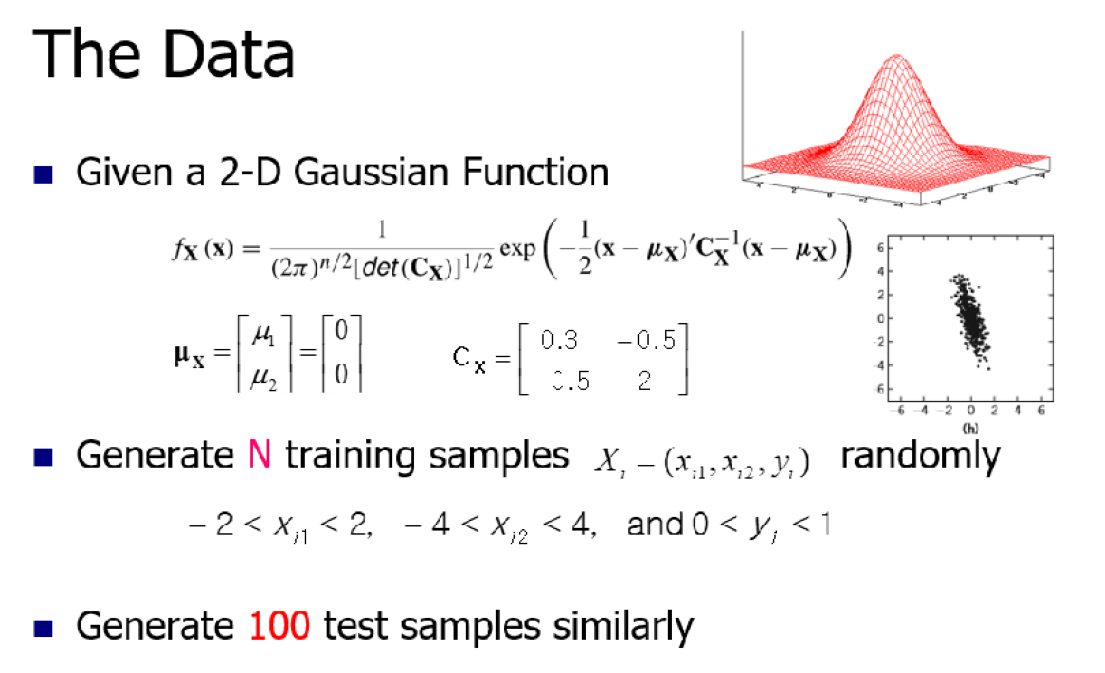

In [ ]:
image = plt.imread("img/ex1.png")
plt.figure(figsize=(14,14))
plt.axis("off"), plt.imshow(image);

In [ ]:
rangex1 = (-2,2)
rangex2 = (-4,4)
mean = np.array([0.0,0.0])
cov = np.array([[0.3,-0.5],[-0.5,2]])

generate_data(n=20000, r1=rangex1, r2=rangex2, m=mean, c=cov, export_path="./data/train.csv", verbose = 1);
generate_data(n=100, r1=rangex1, r2=rangex2, m=mean, c=cov, export_path="./data/test.csv", verbose = 1);
generate_data(n=100, r1=rangex1, r2=rangex2, m=mean, c=cov, export_path="./data/valid.csv", verbose = 1);

x1:  -1.9998842929824545 1.9998484158318028
x2:  -3.9994444615323577 3.999704606590293
x shape:  (20000, 2)
y:  4.094407053216606e-14 0.26894494974987637
y shape:  (20000,)
x1:  -1.9678773049441523 1.8559085465824356
x2:  -3.958162346830905 3.9714534485225688
x shape:  (100, 2)
y:  8.518136862480197e-10 0.24520091605213612
y shape:  (100,)
x1:  -1.9976059432974989 1.9362787717142664
x2:  -3.839433000922722 3.9979439204223413
x shape:  (100, 2)
y:  5.507730069258994e-13 0.2142864834212932
y shape:  (100,)


In [ ]:
x_train, y_train, x_valid, y_valid, x_test, y_test = load_dataset(csv_train="./data/train.csv", csv_valid="./data/valid.csv", csv_test="./data/test.csv")

Training samples:  20000  -- Shape:  (20000, 2) (20000,)
Validating samples:  100  -- Shape:  (100, 2) (100,)
Testing samples:  100  -- Shape:  (100, 2) (100,)


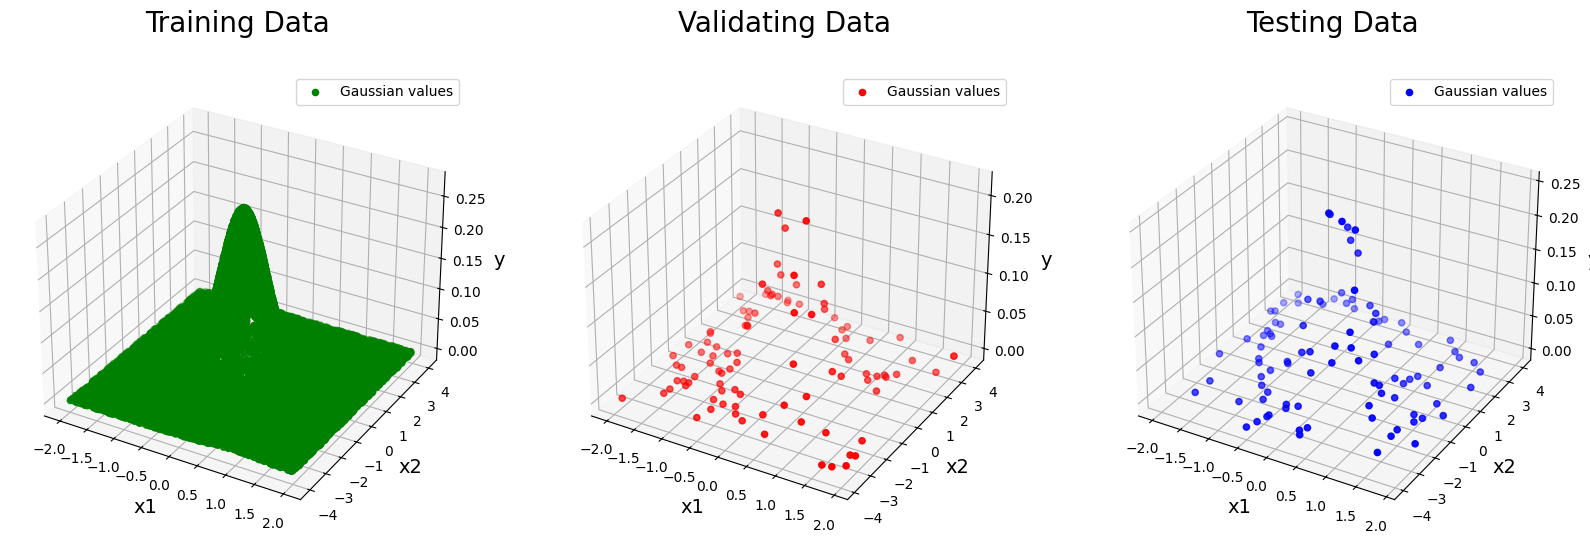

In [ ]:
print("Training samples: ", len(x_train), " -- Shape: ", x_train.shape, y_train.shape)
print("Validating samples: ", len(x_valid), " -- Shape: ", x_valid.shape, y_valid.shape)
print("Testing samples: ", len(x_test), " -- Shape: ", x_test.shape, y_test.shape)

plt.figure(figsize=(20, 6))

ax1 = plt.subplot(1,3,1, projection='3d')
visualize_dataset(x_train, y_train, color = "green", title = "Training Data\n", ax = ax1)

ax2 = plt.subplot(1,3,2, projection='3d')
visualize_dataset(x_valid, y_valid, color = "red", title = "Validating Data\n", ax = ax2)

ax3 = plt.subplot(1,3,3, projection='3d')
visualize_dataset(x_test, y_test, color = "blue", title = "Testing Data\n", ax = ax3)

In [ ]:
x_train, x_valid, x_test = normalize_data(x_train, x_valid, x_test)

*******************
Befor Normalization
*******************
Train min=-3.999, max=4.000
Valid min=-3.839, max=3.998
Test min=-3.958, max=3.971



Mean = [-0.00081453 -0.01191079], Std = [1.15958126 2.30284086]
*******************
After Normalization
*******************
Train min=-1.732, max=1.742
Valid min=-1.722, max=1.741
Test min=-1.714, max=1.730


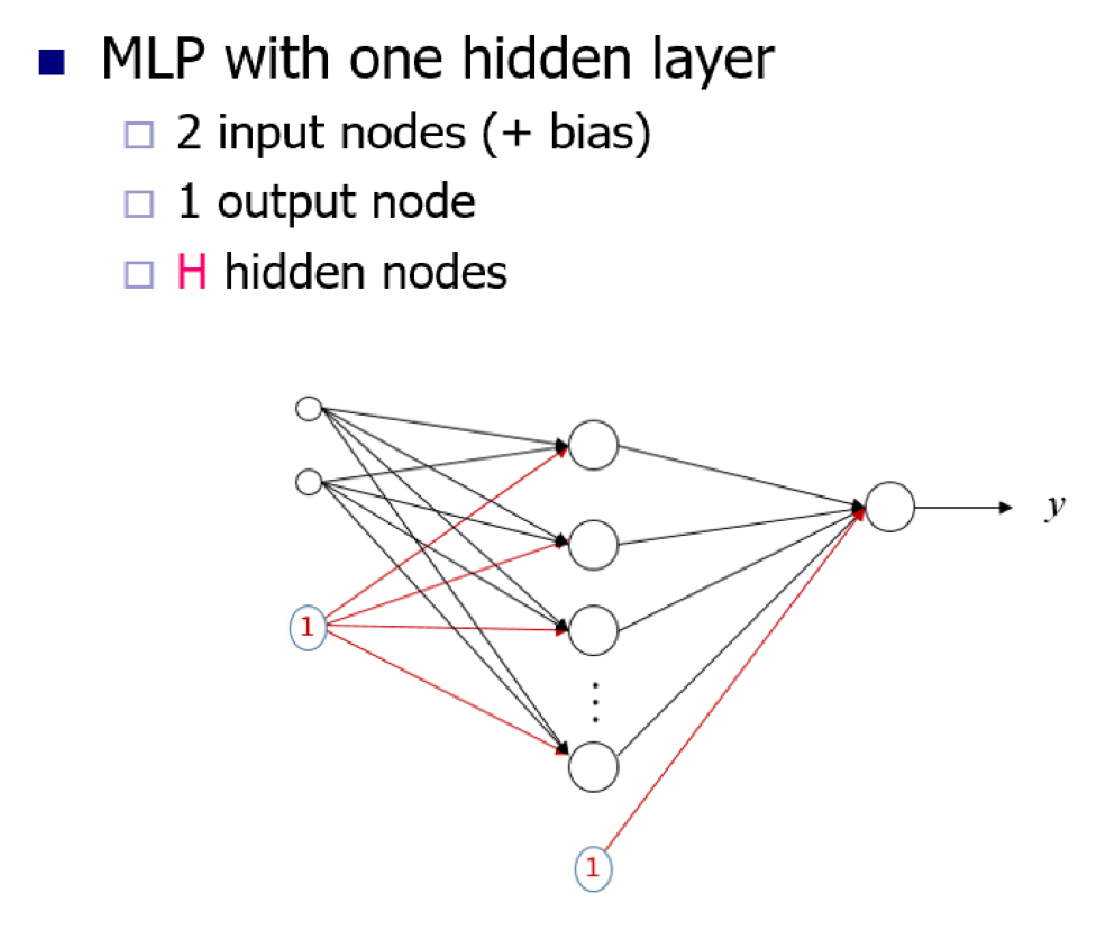

In [ ]:
image = plt.imread("img/model.png")
plt.figure(figsize=(14,14))
plt.axis("off"), plt.imshow(image);

In [ ]:
def build_model(H=10):
    inp = Input(shape=(2,), name='Input')
    x = Dense(units=H, activation='sigmoid', name='fc')(inp)
    output_label = Dense(units=1, activation='sigmoid', name='gauss_apxm')(x)
    
    model = Model(inputs=inp, outputs=output_label)
    model.summary()
    return model

In [ ]:
# build a sample model with hidden node = 10
model = build_model(H=10)

NameError: name 'Input' is not defined

Train: x-shape = (200, 2) y-shape = (200,)
Valid: x-shape = (100, 2) y-shape = (100,)


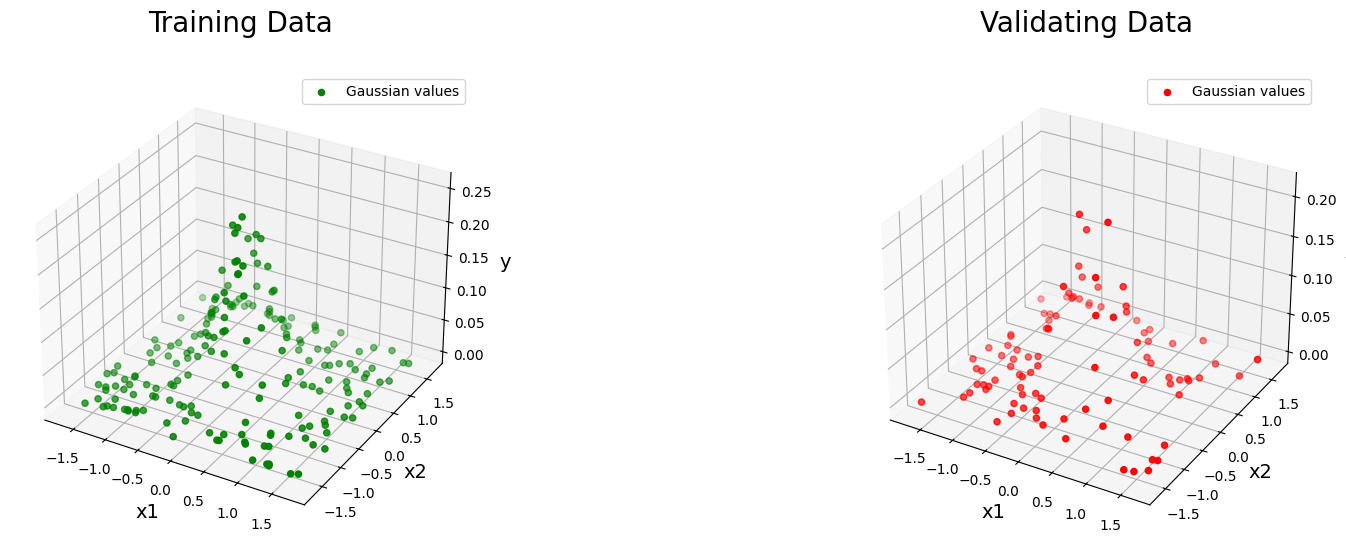

In [ ]:
x_exp1_train, y_exp1_train = x_train[:200], y_train[:200]
x_exp1_valid, y_exp1_valid = x_valid, y_valid

print(f"Train: x-shape = {x_exp1_train.shape} y-shape = {y_exp1_train.shape}")
print(f"Valid: x-shape = {x_exp1_valid.shape} y-shape = {y_exp1_valid.shape}")

plt.figure(figsize=(20, 6))

ax1 = plt.subplot(1,2,1, projection='3d')
visualize_dataset(x_exp1_train, y_exp1_train, color = "green", title = "Training Data\n", ax = ax1)

ax2 = plt.subplot(1,2,2, projection='3d')
visualize_dataset(x_exp1_valid, y_exp1_valid, color = "red", title = "Validating Data\n", ax = ax2)

In [ ]:
exp1_model = build_model(H=10)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input (InputLayer)              │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc (Dense)                      │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gauss_apxm (Dense)              │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41 (164.00 B)

 Trainable params: 41 (164.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
K.clear_session()
exp1_model = build_model(H=10)

# OPTIMIZATION
exp1_model.compile(loss='mean_squared_error', optimizer=SGD(lr=0.01), metrics=['mean_squared_error'])

# CALLBACKS
callbacks = []

# + ModelCheckPoint
save_dir = "./data/model/train_01"
template_name= "funcApxm_model_01_{epoch:02d}_{val_loss:.3f}_val_acc-{val_mean_squared_error:.3f}.h5"
if os.path.exists(save_dir) == False: os.makedirs(save_dir)
modekcheckpoint_callback = ModelCheckpoint(filepath = os.path.join(save_dir, template_name),
                                           monitor='val_loss', 
                                           verbose=0, 
                                           save_best_only=True, 
                                           save_weights_only=False, # only weight, 
                                           mode='auto', # min, max, auto
                                           period=1  # bao nhieu epoch moi xem xet 1 lan
                                          )
callbacks.append(modekcheckpoint_callback)

# + Early Stopping
earlystopping_callback = EarlyStopping(monitor='val_loss', patience= 10)
callbacks.append(earlystopping_callback)


# + Visualize logs
review_logs = {}
def custom_on_epoch_end(self, epoch, logs, **kwargs):  
    review_logs = kwargs["review_logs"]
    if epoch == 0:
        review_logs["epoch"] = [epoch]
        for key in logs.keys(): review_logs[key] = [logs[key]]
    # if
    review_logs["epoch"].append(epoch)
    for key in logs.keys(): review_logs[key].append(logs[key])
    
    visualize_data = review_logs
    group_view     = [{"x": "epoch", "y": ["loss", "val_loss"], 
                       "title": "Loss at Epoch {epoch}: {val_loss:.6f}\n", 
                       "style": "median"}, 
                      {"x": "epoch", "y": ["mean_squared_error", "val_mean_squared_error"], 
                       "title": "MSE at Epoch {epoch}: {val_mean_squared_error:.6f}\n", 
                       "style": None}
                     ]
    fig = visualize_logs(visualize_data, group_view, figsize = (10, 6), is_show = False, save_path = os.path.join("./data/model/train_01", "logs.png"))
    plt.close()
    if epoch == 0:
        display.display(fig, display_id="logs")
    else:
        display.update_display(fig, display_id="logs")
    pass
# custom_on_epoch_end

custom_callbacks = LambdaCallback()
custom_callbacks.on_epoch_end = lambda epoch, logs: custom_on_epoch_end(custom_callbacks, epoch, logs, review_logs = review_logs)
callbacks.append(custom_callbacks)

# TRAINING
batch_size = 128
epochs = 200

starting_time = time.time()
history = exp1_model.fit(x_exp1_train, y_exp1_train,
                    validation_data=(x_exp1_valid, y_exp1_valid),
                    batch_size=batch_size,
                    epochs=epochs, 
                    callbacks = callbacks, 
                    verbose = 0)
print('> training time is %.4f minutes' % ((time.time() - starting_time)/60))

NameError: name 'K' is not defined

In [ ]:
epoch_opt = np.argmin(history.history["val_mean_squared_error"])

In [ ]:
save_name = template_name.format(epoch = epoch_opt + 1, 
                 val_mean_squared_error = history.history["val_mean_squared_error"][epoch_opt], 
                 val_loss= history.history["val_loss"][epoch_opt])
save_path = os.path.join(save_dir, save_name)
save_path

In [ ]:
from keras.models import load_model
model = load_model(save_path)
score = model.evaluate(x_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])
summarize_diagnostics(history)

4. Thực nghiệm B

In [ ]:
image = plt.imread("img/ex2.png")
plt.figure(figsize=(14,14))
plt.axis("off"), plt.imshow(image);

In [ ]:
x_exp2_train, y_exp2_train = [], []
x_exp2_valid, y_exp2_valid = x_valid, y_valid
print("Train: ")
for size in range(200, 2001, 200):
    x_exp2_train.append(x_train[:size])
    y_exp2_train.append(y_train[:size])
    print(f"+ Size: {size} {x_exp2_train[-1].shape} {y_exp2_train[-1].shape}")
# for
print(f"Valid: {x_exp2_valid.shape} {y_exp2_valid.shape}")

In [ ]:
exp2_model = build_model(H = 10)

In [ ]:
def train_model(train_id, x_local_train, y_local_train, 
                x_local_valid, y_local_valid, nb_epochs = 1000):
    
    K.clear_session()
    exp2_model = build_model(H=10)

    # OPTIMIZATION
    exp2_model.compile(loss='mean_squared_error', optimizer=SGD(lr=0.01), metrics=['mean_squared_error'])

    # CALLBACKS
    callbacks = []

    # + ModelCheckPoint
    save_dir = f"./data/model/train_02/{train_id}"
    if os.path.exists(save_dir)==False: os.makedirs(save_dir)
    template_name= "funcApxm_model_01_{epoch:02d}_{val_loss:.3f}_val_acc-{val_mean_squared_error:.3f}.h5"
    if os.path.exists(save_dir) == False: os.makedirs(save_dir)
    modekcheckpoint_callback = ModelCheckpoint(filepath = os.path.join(save_dir, template_name),
                                               monitor='val_loss', 
                                               verbose=0, 
                                               save_best_only=True, 
                                               save_weights_only=False, # only weight, 
                                               mode='auto', # min, max, auto
                                               period=1  # bao nhieu epoch moi xem xet 1 lan
                                              )
    callbacks.append(modekcheckpoint_callback)

    # + Early Stopping
    # earlystopping_callback = EarlyStopping(monitor='val_loss', patience= 10)
    # callbacks.append(earlystopping_callback)

    # + Visualize logs
    review_logs = {}
    def custom_on_epoch_end(self, epoch, logs, **kwargs):   
        review_logs = kwargs["review_logs"]
        if epoch == 0:
            review_logs["epoch"] = [epoch]
            for key in logs.keys(): review_logs[key] = [logs[key]]
        # if
        review_logs["epoch"].append(epoch)
        for key in logs.keys(): review_logs[key].append(logs[key])

        visualize_data = review_logs
        group_view     = [{"x": "epoch", "y": ["loss", "val_loss"], 
                           "title": "Loss at Epoch {epoch}: {val_loss:.6f}\n", 
                           "style": "median"}, 
                          {"x": "epoch", "y": ["mean_squared_error", "val_mean_squared_error"], 
                           "title": "MSE at Epoch {epoch}: {val_mean_squared_error:.6f}\n", 
                           "style": None}
                         ]
        fig = visualize_logs(visualize_data, group_view, figsize = (10, 6), is_show = False, 
                             save_path = os.path.join(f"./data/model/train_02/{train_id}", "logs.png"))
        plt.close()
        if epoch == 0:
            display.display(fig, display_id=f"logs_{train_id}")
        else:
            display.update_display(fig, display_id=f"logs_{train_id}")
        pass
    # custom_on_epoch_end

    custom_callbacks = LambdaCallback()
    custom_callbacks.on_epoch_end = lambda epoch, logs: custom_on_epoch_end(custom_callbacks, epoch, logs, review_logs = review_logs)
    callbacks.append(custom_callbacks)

    # TRAINING
    batch_size = 128
    epochs = nb_epochs

    starting_time = time.time()
    history = exp2_model.fit(x_local_train, y_local_train,
                        validation_data=(x_local_valid, y_local_valid),
                        batch_size=batch_size,
                        epochs=epochs, 
                        callbacks = callbacks, 
                        verbose = 0)
    print('> training time is %.4f minutes' % ((time.time() - starting_time)/60))
    return history
# train_model

In [ ]:
history = []
for i in range(len(x_exp2_train)):
    print(f"Train id: {i}")
    temp_history = train_model(i, x_exp2_train[i], y_exp2_train[i], x_exp2_valid, y_exp2_valid, nb_epochs = 200)
    history.append(temp_history)
# for

4.4. Evaluating

In [ ]:
errors = []
for i in range(len(history)):
    epoch_opt = np.argmin(history[i].history["val_mean_squared_error"])
    error = history[i].history["val_mean_squared_error"][epoch_opt]
    errors.append(error)
# for
sizes = list(range(200, 2001, 200))

In [ ]:
vt_min = np.argmin(np.array(errors))
print(f"Min Error at size={sizes[vt_min]} with error = {errors[vt_min]}")

In [ ]:
plt.plot(sizes, errors)
plt.xlabel("Size", fontsize = 14)
plt.ylabel("Error", fontsize = 14)
plt.title("Performance against the # of training samples\n", fontsize = 14);

5. Thực nghiệm C

In [ ]:
image = plt.imread("img/exp3.png")
plt.figure(figsize=(14,14))
plt.axis("off"), plt.imshow(image);

In [ ]:
x_exp3_train, y_exp3_train = x_train[:1800], y_train[:1800]
x_exp3_valid, y_exp3_valid = x_valid, y_valid

print(f"Train: x-shape = {x_exp3_train.shape} y-shape = {y_exp3_train.shape}")
print(f"Valid: x-shape = {x_exp3_valid.shape} y-shape = {y_exp3_valid.shape}")

plt.figure(figsize=(20, 6))

ax1 = plt.subplot(1,2,1, projection='3d')
visualize_dataset(x_exp3_train, y_exp3_train, color = "green", title = "Training Data\n", ax = ax1)

ax2 = plt.subplot(1,2,2, projection='3d')
visualize_dataset(x_exp3_valid, y_exp3_valid, color = "red", title = "Validating Data\n", ax = ax2)

In [ ]:
exp3_model = build_model(H=10)

In [ ]:
def train_model(train_id, x_local_train, y_local_train, x_local_valid, y_local_valid, n_hidden = 10, nb_epochs = 1000):
    
    K.clear_session()
    exp3_model = build_model(H=n_hidden)

    # OPTIMIZATION
    exp3_model.compile(loss='mean_squared_error', optimizer=SGD(lr=0.01), metrics=['mean_squared_error'])

    # CALLBACKS
    callbacks = []

    # + ModelCheckPoint
    save_dir = f"./data/model/train_03/{train_id}"
    if os.path.exists(save_dir)==False: os.makedirs(save_dir)
    template_name= "funcApxm_model_01_{epoch:02d}_{val_loss:.3f}_val_acc-{val_mean_squared_error:.3f}.h5"
    if os.path.exists(save_dir) == False: os.makedirs(save_dir)
    modekcheckpoint_callback = ModelCheckpoint(filepath = os.path.join(save_dir, template_name),
                                               monitor='val_loss', 
                                               verbose=0, 
                                               save_best_only=True, 
                                               save_weights_only=False, # only weight, 
                                               mode='auto', # min, max, auto
                                               period=1  # bao nhieu epoch moi xem xet 1 lan
                                              )
    callbacks.append(modekcheckpoint_callback)

    # + Early Stopping
    # earlystopping_callback = EarlyStopping(monitor='val_loss', patience= 10)
    # callbacks.append(earlystopping_callback)

    # + Visualize logs
    review_logs = {}
    def custom_on_epoch_end(self, epoch, logs, **kwargs):   
        review_logs = kwargs["review_logs"]
        if epoch == 0:
            review_logs["epoch"] = [epoch]
            for key in logs.keys(): review_logs[key] = [logs[key]]
        # if
        review_logs["epoch"].append(epoch)
        for key in logs.keys(): review_logs[key].append(logs[key])

        visualize_data = review_logs
        group_view     = [{"x": "epoch", "y": ["loss", "val_loss"], 
                           "title": "Loss at Epoch {epoch}: {val_loss:.6f}\n", 
                           "style": "median"}, 
                          {"x": "epoch", "y": ["mean_squared_error", "val_mean_squared_error"], 
                           "title": "MSE at Epoch {epoch}: {val_mean_squared_error:.6f}\n", 
                           "style": None}
                         ]
        fig = visualize_logs(visualize_data, group_view, figsize = (10, 6), is_show = False, 
                             save_path = os.path.join(f"./data/model/train_03/{train_id}", "logs.png"))
        plt.close()
        if epoch == 0:
            display.display(fig, display_id=f"logs_{train_id}")
        else:
            display.update_display(fig, display_id=f"logs_{train_id}")
        pass
    # custom_on_epoch_end

    custom_callbacks = LambdaCallback()
    custom_callbacks.on_epoch_end = lambda epoch, logs: custom_on_epoch_end(custom_callbacks, epoch, logs, review_logs = review_logs)
    callbacks.append(custom_callbacks)

    # TRAINING
    batch_size = 128
    epochs = nb_epochs

    starting_time = time.time()
    history = exp3_model.fit(x_local_train, y_local_train,
                        validation_data=(x_local_valid, y_local_valid),
                        batch_size=batch_size,
                        epochs=epochs, 
                        callbacks = callbacks, 
                        verbose = 0)
    print('> training time is %.4f minutes' % ((time.time() - starting_time)/60))
    return history
# train_model

In [ ]:
history = []
for i in range(1, 11, 1):
    print(f"Train id: {i}")
    temp_history = train_model(i, x_exp3_train, y_exp3_train, x_exp3_valid, y_exp3_valid, n_hidden=i, nb_epochs = 200)
    history.append(temp_history)
# for

5.4. Evaluating

In [ ]:
errors = []
for i in range(len(history)):
    epoch_opt = np.argmin(history[i].history["val_mean_squared_error"])
    error = history[i].history["val_mean_squared_error"][epoch_opt]
    errors.append(error)
# for
hiddens = list(range(1, 11, 1))

In [ ]:
vt_min = np.argmin(np.array(errors))
print(f"Min Error at n_hidden={hiddens[vt_min]} with error = {errors[vt_min]}")

In [ ]:
plt.plot(hiddens, errors)
plt.xlabel("Number of hidden nodes", fontsize = 14)
plt.ylabel("Error", fontsize = 14)
plt.title("Performance against the # of training samples\n", fontsize = 14);